In [168]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
import warnings
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

In [169]:
# 1. Read the file.
df = pd.read_csv('C:/Users/nickt/Downloads/ECO482 Assignment 1/mobile_money.csv')

In [170]:
# 2. Descriptive statistics for mpesa_user
print(df['mpesa_user'].describe().T)

count     2282
unique       2
top        yes
freq      1676
Name: mpesa_user, dtype: object


In [171]:
# Descriptive statistics on many variables depending on mpesa_user status (Yes or No)

# remove variables with lots of missing data
missing_counts = df.isnull().sum()

for var, count in missing_counts.items():
    if count > 200:
        df.drop(var, axis=1, inplace=True)

# remove hhid's who have missing data
df.dropna(inplace=True)

all_missing_counts = df.isnull().sum()

pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.max_columns', None)

# Filter to only show columns that have at least one missing entry
columns_with_missing = all_missing_counts[all_missing_counts > 0]
print("Full list of all variables with missing data:")
print(columns_with_missing)

df['bank_acct'] = (df['bank_acct'] == 'yes').astype(int)
df['mattress'] = (df['mattress'] == 'yes').astype(int)
df['sacco'] = (df['sacco'] == 'yes').astype(int)
df['merry'] = (df['sacco'] == 'yes').astype(int)

analysis_vars = [
    'cellphone', 'totexppc', 'wkexppc', 'wealth', 'size',
    'education_years', 'pos', 'neg', 'ag', 'sick',
    'sendd', 'recdd', 'bank_acct', 'mattress', 'sacco',
    'merry', 'occ_farmer', 'occ_public', 'occ_prof', 'occ_help',
    'occ_bus', 'occ_sales', 'occ_ind', 'occ_other', 'occ_ue'
]

for var in analysis_vars:
    df[var] = pd.to_numeric(df[var], errors='coerce')
df[analysis_vars] = df[analysis_vars].fillna(0)

# when mpesa_user = yes
print('Descriptive Statistics for mpesa_user = yes')
print(df[df['mpesa_user'] == 'yes'][analysis_vars].describe().T)
# when mpesa_user = no
print('Descriptive Statistics for mpesa_user = no')
print(df[df['mpesa_user'] == 'no'][analysis_vars].describe().T)

Full list of all variables with missing data:
Series([], dtype: int64)
Descriptive Statistics for mpesa_user = yes
                  count           mean           std     min         25%        50%         75%         max
cellphone        1666.0       0.923169  2.664026e-01     0.0      1.0000      1.000       1.000         1.0
totexppc         1666.0   84480.476127  1.029808e+05  2306.0  34404.5225  57171.600   98635.000   1870776.0
wkexppc          1666.0   35489.424210  2.796959e+04  1397.5  18404.5375  27712.535   42703.145    263380.0
wealth           1666.0  215052.112245  1.461410e+06   350.0  25000.0000  54000.000  112800.000  47200000.0
size             1666.0       4.263505  2.176771e+00     1.0      3.0000      4.000       6.000        13.0
education_years  1666.0       8.373950  5.289007e+00     0.0      5.0000      9.000      12.000        19.0
pos              1666.0       0.072629  2.596046e-01     0.0      0.0000      0.000       0.000         1.0
neg              1666

In [172]:
# 4. Constructing classifiers using the outcome variable mpesa_user

df['mpesa_user'] = (df['mpesa_user'] == 'yes').astype(int)

Y = df['mpesa_user']
X = df.select_dtypes(include=['number']).drop(['mpesa_user'], axis=1)

# Split the dataset
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# Scale the data so each feature are on a similar scale.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Logistic Regression Classifier
logreg = LogisticRegression()
logreg.fit(X_train, Y_train)
y_pred_logistic = logreg.predict(X_test)

# Random Forest Classifier
clf = RandomForestClassifier(max_depth=20, random_state=42)
clf.fit(X_train, Y_train)
y_pred_forest = clf.predict(X_test)

# Linear Discriminant Analysis
lda = LinearDiscriminantAnalysis(n_components=1)
X_train_lda = lda.fit_transform(X_train, Y_train)
X_test_lda = lda.transform(X_test)

In [173]:
# a) get accuracy from each model.
logreg_accuracy = logreg.score(X_test, Y_test)
clf_accuracy = clf.score(X_test, Y_test)
lda_accuracy = lda.score(X_test, Y_test)

# b) get area under the curve (AUC) criteria.
y_probs_logreg = logreg.predict_proba(X_test)[:, 1]
auc_score_logreg = roc_auc_score(Y_test, y_probs_logreg)

y_probs_clf = clf.predict_proba(X_test)[:, 1]
auc_score_clf = roc_auc_score(Y_test, y_probs_clf)

y_probs_lda = lda.predict_proba(X_test)[:, 1]
auc_score_lda = roc_auc_score(Y_test, y_probs_lda)

print(f"Model: {logreg}, Accuracy: {logreg_accuracy:.4f}, AUC: {auc_score_logreg:.4f}")
print(f"Model: {clf}, Accuracy: {clf_accuracy:.4f}, AUC: {auc_score_clf:.4f}")
print(f"Model: {lda}, Accuracy: {lda_accuracy:.4f}, AUC: {auc_score_lda:.4f}")

Model: LogisticRegression(), Accuracy: 0.9246, AUC: 0.9576
Model: RandomForestClassifier(max_depth=20, random_state=42), Accuracy: 0.9091, AUC: 0.9420
Model: LinearDiscriminantAnalysis(n_components=1), Accuracy: 0.9091, AUC: 0.9486


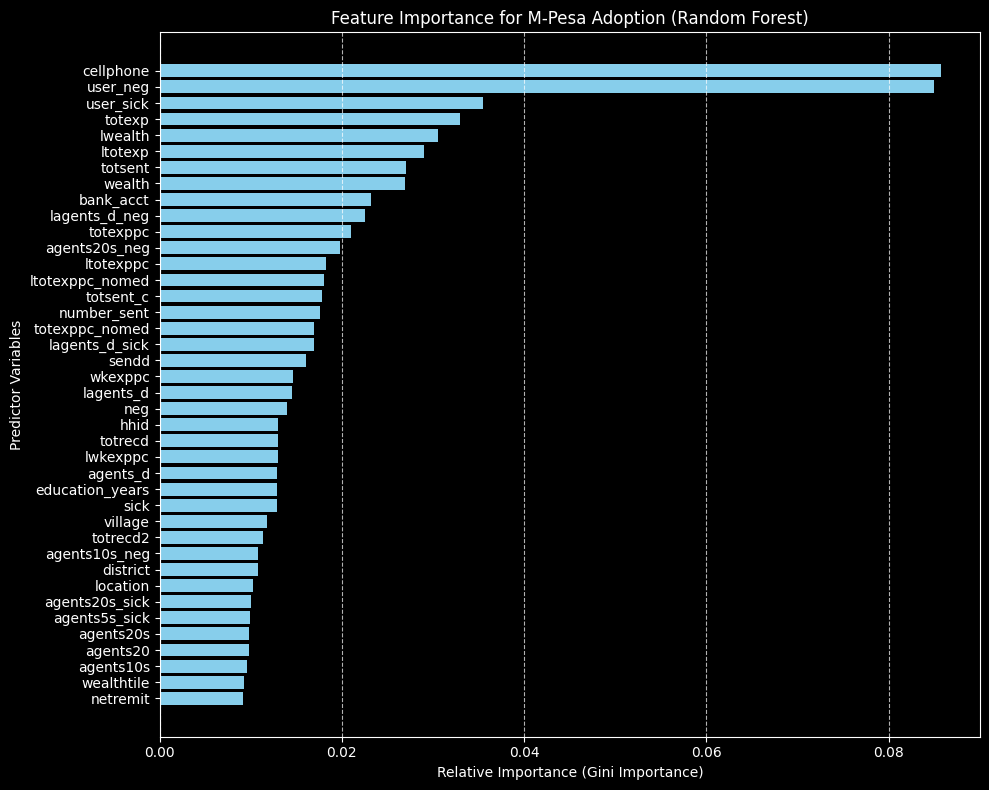

In [174]:
# 6: plot importance of each predictor for random forest model
# Extract importance scores from your trained RandomForest model

feature_names = X.columns
importances = clf.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=True).tail(40)

# Create the plot
plt.figure(figsize=(10, 8))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='skyblue')
plt.xlabel('Relative Importance (Gini Importance)')
plt.ylabel('Predictor Variables')
plt.title('Feature Importance for M-Pesa Adoption (Random Forest)')
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Display the plot
plt.tight_layout()
plt.show()

In [175]:
# 7) Create a KNN classifier with say, K=5 then optimize for K.

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, Y_train)
y_pred = knn.predict(X_test)

k_results = {}

for k in range(1, 11):
    model = make_pipeline(scaler, KNeighborsClassifier(n_neighbors=k))
    # Get the average score for this K
    scores = cross_val_score(model, X_train, Y_train, cv=5)
    k_results[k] = scores.mean()
    print(f"K={k}: Accuracy = {scores.mean():.4f}")

best_k = max(k_results, key=k_results.get)
print(f"The optimal K is: {best_k}")


K=1: Accuracy = 0.8013
K=2: Accuracy = 0.7697
K=3: Accuracy = 0.8274
K=4: Accuracy = 0.8257
K=5: Accuracy = 0.8557
K=6: Accuracy = 0.8441
K=7: Accuracy = 0.8613
K=8: Accuracy = 0.8507
K=9: Accuracy = 0.8602
K=10: Accuracy = 0.8590
The optimal K is: 7


In [176]:
# 8) Fine-tune the logistic model by cross-validating penality and C

# We use solver='saga' because it supports both l1 and l2
logreg_tune = LogisticRegression(solver='saga', max_iter=10000, random_state=42)

# Define the exact parameters requested
param_grid = {
    'penalty': ['l1', 'l2'],
    'C': [0.1, 1, 10, 100]
}

search = GridSearchCV(logreg_tune, param_grid, cv=5)
search.fit(X_train, Y_train)

results_df = pd.DataFrame(search.cv_results_)
relevant_cols = ['param_penalty', 'param_C', 'mean_test_score']
print(results_df[relevant_cols].sort_values(by='mean_test_score', ascending=False))

print(f"\nBest Parameters: {search.best_params_}")

  param_penalty  param_C  mean_test_score
5            l2     10.0         0.924523
4            l1     10.0         0.923969
3            l2      1.0         0.921745
6            l1    100.0         0.921193
7            l2    100.0         0.921193
1            l2      0.1         0.920639
0            l1      0.1         0.920080
2            l1      1.0         0.920078

Best Parameters: {'C': 10, 'penalty': 'l2'}


In [177]:
# 9)

C_values = [0.1, 1, 10, 100]
print(f"{'C Value':<10} | {'Average Coefficient Magnitude':<30}")
print("-" * 45)

for C_val in C_values:
    model = LogisticRegression(C=C_val, solver='saga', penalty='l1', max_iter=10000, random_state=42)
    model.fit(X_train, Y_train)
    avg_coef = np.mean(np.abs(model.coef_))

    print(f"{C_val:<10} | {avg_coef:.4f}")

C Value    | Average Coefficient Magnitude 
---------------------------------------------
0.1        | 0.1027
1          | 0.2666
10         | 0.4473
100        | 0.4925
